
video                 : task10_motion.mp4
size                  : 1080x1920
fps                   : 30.01
frames_read           : 992
frames_reported       : 992
duration_s            : 33.1
empty_start_pct       : 0.0
max_shift_px          : 0.1
max_brightness_jump   : 3.51
noise_pct             : 0.0
peak_motion_pct       : 40.0
end_motion_pct        : 0.35
  OK   readable
  OK   fps_ok
  OK   empty_start
  OK   camera_still
  OK   light_stable
  OK   low_noise
  OK   empty_end


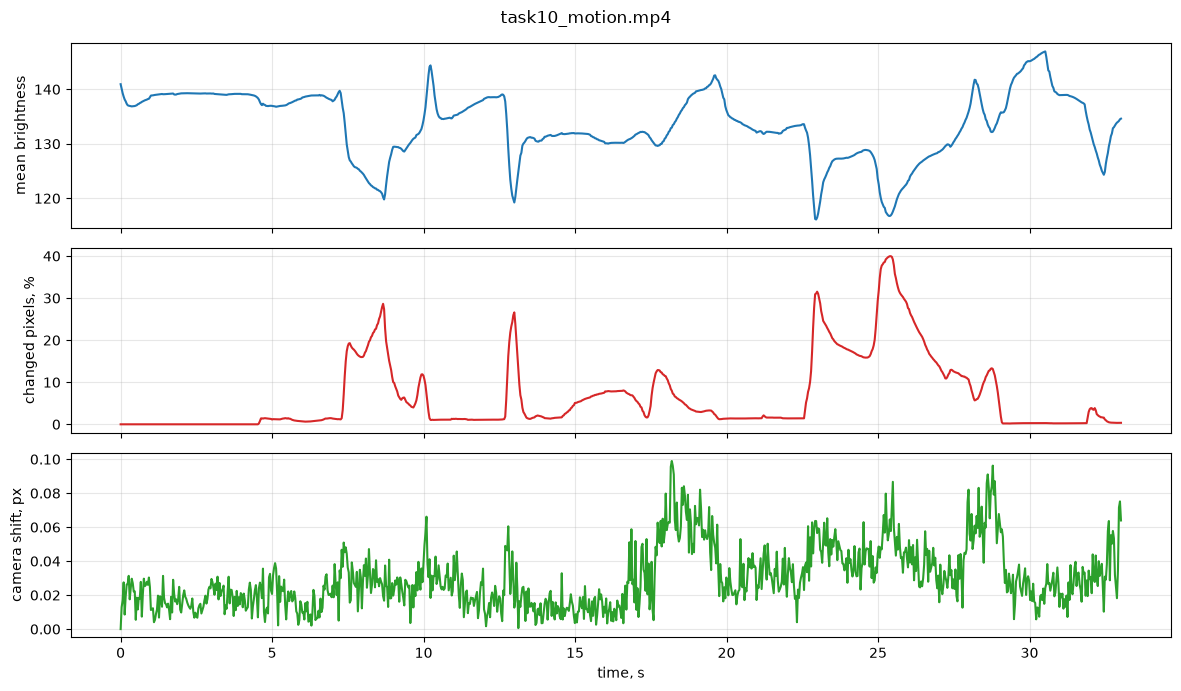

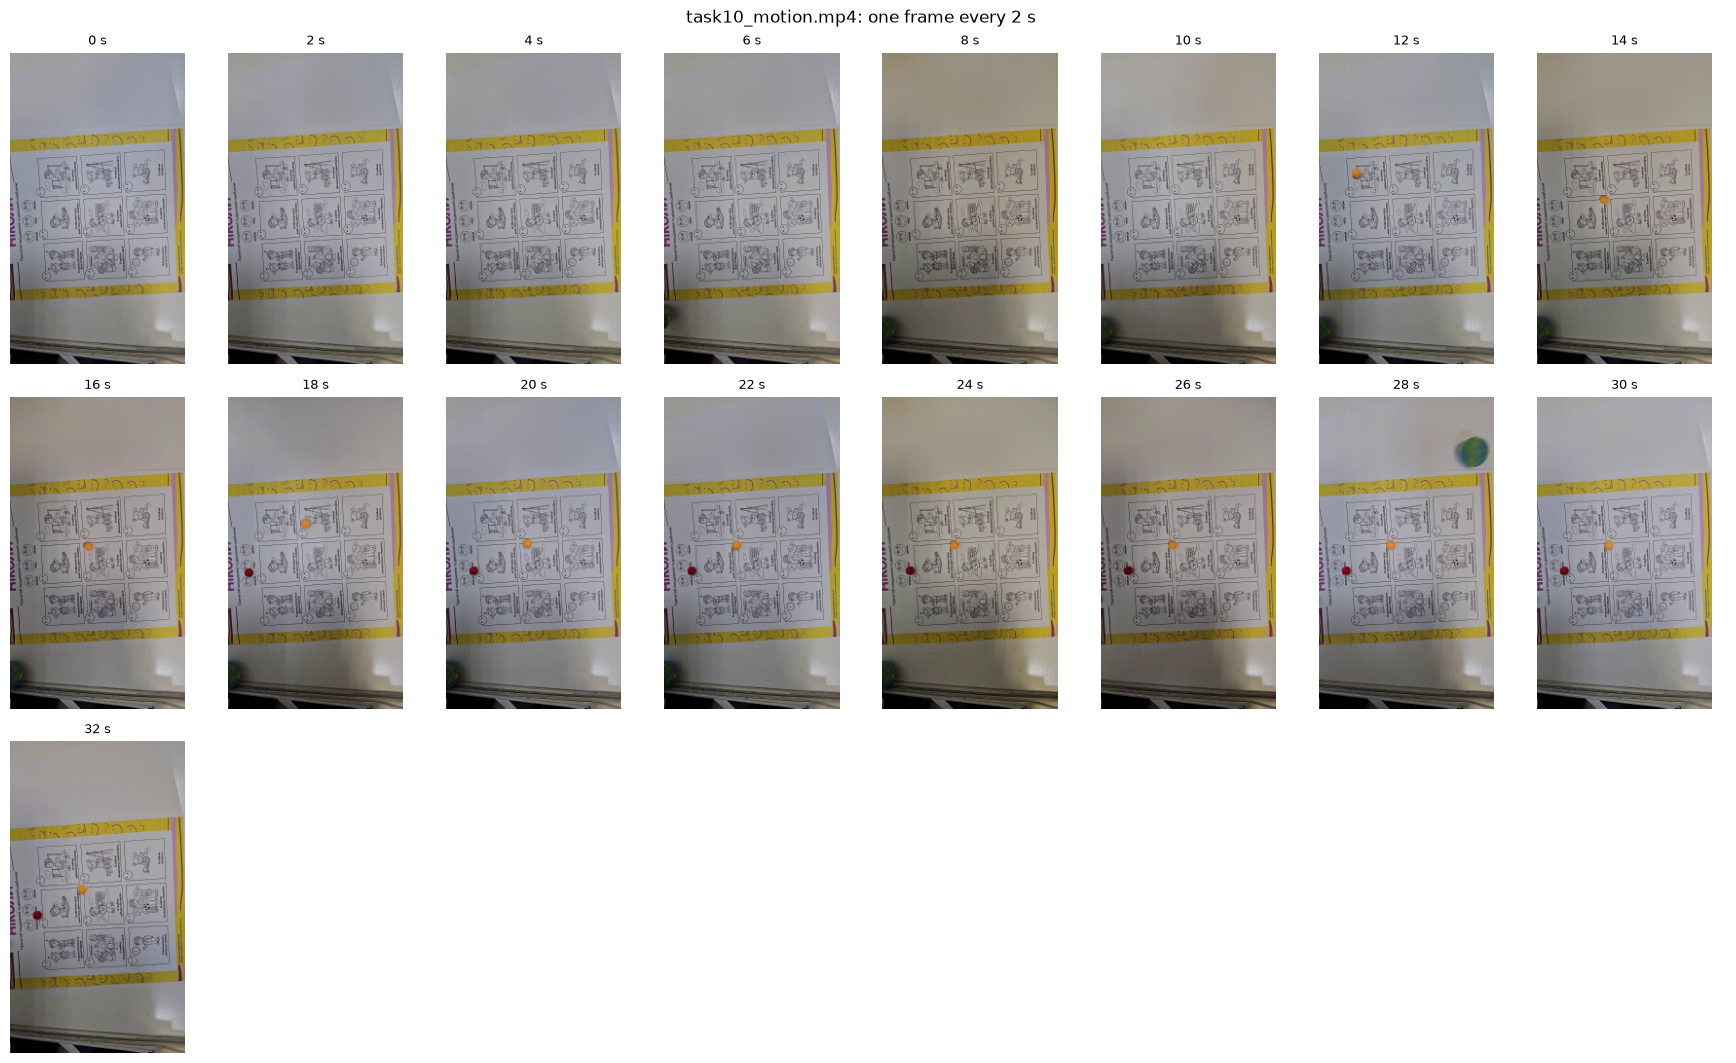

In [8]:
import cv2, numpy as np, matplotlib.pyplot as plt
from pathlib import Path

VIDEO = [Path("data") / "task10_motion.mp4"]
SMALL, THR = 320, 25                                   # analysis size (longer side, px), change threshold
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)

def small(frame):
    h, w = frame.shape[:2]; s = SMALL / max(h, w)
    return cv2.resize(frame, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)

def check_video(path):
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        return {"video": path.name, "error": "cannot open"}, None
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    n_rep = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    ref = prev = None
    t, bright, motion, shift, noise, thumbs = [], [], [], [], [], []
    i, step = 0, int(round(2 * fps))
    while True:
        ok, f = cap.read()
        if not ok: break
        sm = small(f)
        g = cv2.GaussianBlur(cv2.cvtColor(sm, cv2.COLOR_BGR2GRAY), (5, 5), 0)
        if ref is None: ref, ref_f = g, g.astype(np.float32)
        t.append(i / fps); bright.append(g.mean())
        motion.append(100 * np.mean(cv2.absdiff(g, ref) > THR))
        (dx, dy), _ = cv2.phaseCorrelate(ref_f, g.astype(np.float32)); shift.append(np.hypot(dx, dy))
        if prev is not None and i / fps < 2.0:
            noise.append(100 * np.mean(cv2.absdiff(g, prev) > THR))
        if i % step == 0: thumbs.append((i / fps, cv2.cvtColor(sm, cv2.COLOR_BGR2RGB)))
        prev, i = g, i + 1
    cap.release()

    i2 = min(int(2 * fps), len(motion) - 1)
    s = dict(video=path.name, size=f"{W}x{H}", fps=round(fps, 2), frames_read=i, frames_reported=n_rep,
             duration_s=round(i / fps, 1),
             empty_start_pct=round(motion[i2], 2),
             max_shift_px=round(max(shift), 2),
             max_brightness_jump=round(float(np.max(np.abs(np.diff(bright)))), 2),
             noise_pct=round(float(np.mean(noise)), 2) if noise else None,
             peak_motion_pct=round(max(motion), 1), end_motion_pct=round(motion[-1], 2))
    s["verdict"] = {
        "readable":     abs(i - n_rep) <= 2,
        "fps_ok":       25 <= fps <= 31,
        "empty_start":  s["empty_start_pct"] < 0.5,
        "camera_still": s["max_shift_px"] < 2,
        "light_stable": s["max_brightness_jump"] < 4,
        "low_noise":    (s["noise_pct"] or 0) < 0.5,
        "empty_end":    s["end_motion_pct"] < 0.5}
    return s, (np.array(t), np.array(bright), np.array(motion), np.array(shift), thumbs)

for path in VIDEO:
    s, data = check_video(path)
    print("\n" + "=" * 70); [print(f"{k:22s}: {v}") for k, v in s.items() if k != "verdict"]
    if data is None: continue
    for k, v in s["verdict"].items(): print(f"  {'OK  ' if v else 'FAIL'} {k}")

    t, bright, motion, shift, thumbs = data
    fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
    ax[0].plot(t, bright); ax[0].set_ylabel("mean brightness")
    ax[1].plot(t, motion, color="tab:red"); ax[1].set_ylabel("changed pixels, %")
    ax[2].plot(t, shift, color="tab:green"); ax[2].set_ylabel("camera shift, px"); ax[2].set_xlabel("time, s")
    for a in ax: a.grid(alpha=0.3)
    fig.suptitle(path.name); plt.tight_layout()
    plt.savefig(RESULTS / f"check_{path.stem}_signals.png", dpi=90); plt.show()

    cols = 8; rows = int(np.ceil(len(thumbs) / cols))
    fig, ax = plt.subplots(rows, cols, figsize=(2.2 * cols, 3.6 * rows))
    for a in np.ravel(ax): a.axis("off")
    for a, (ts, im) in zip(np.ravel(ax), thumbs):
        a.imshow(im); a.set_title(f"{ts:.0f} s", fontsize=9)
    fig.suptitle(f"{path.name}: one frame every 2 s"); plt.tight_layout()
    plt.savefig(RESULTS / f"check_{path.stem}_sheet.png", dpi=90); plt.show()

Frame differencing

read 13 frames from task10_motion.mp4 (fps 30.01)
t=  5.0s  A1 vs reference:  1.01% motion px   A2 vs previous:  0.73% motion px
t= 13.0s  A1 vs reference: 22.35% motion px   A2 vs previous:  0.02% motion px
t= 16.5s  A1 vs reference:  6.47% motion px   A2 vs previous:  0.00% motion px
t= 21.0s  A1 vs reference:  1.32% motion px   A2 vs previous:  0.00% motion px
t= 24.0s  A1 vs reference: 15.23% motion px   A2 vs previous:  0.00% motion px
t= 27.5s  A1 vs reference: 10.40% motion px   A2 vs previous:  1.18% motion px


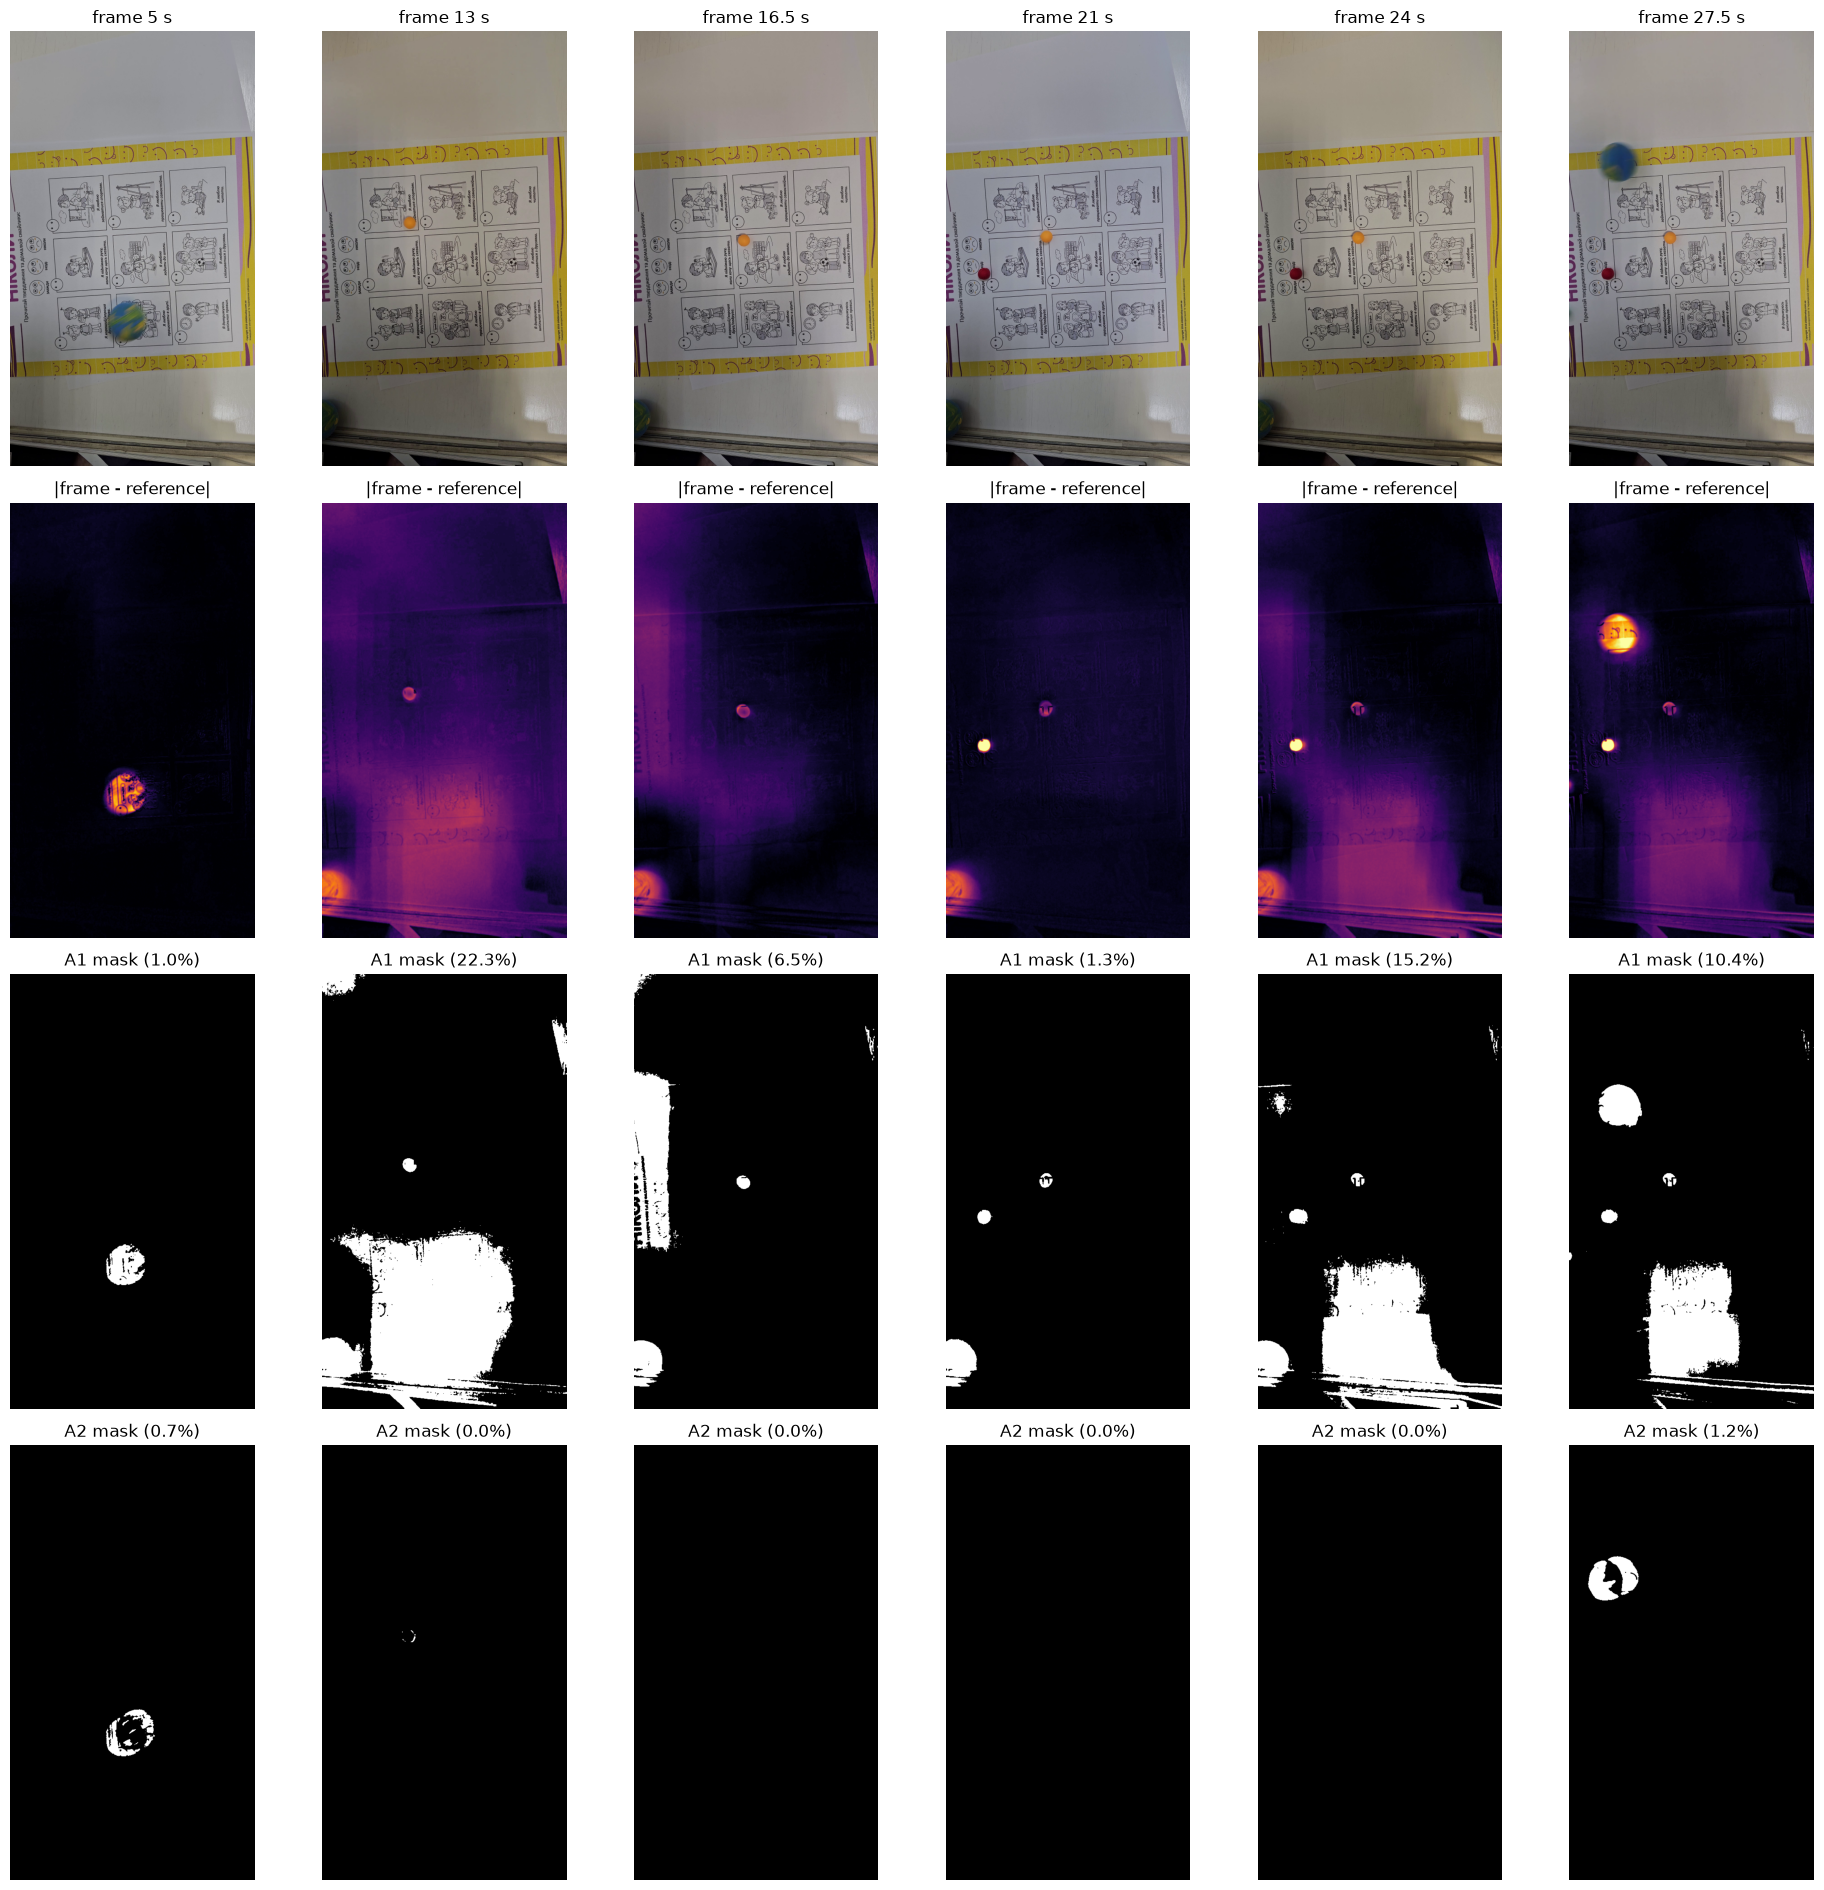

In [12]:
VIDEO = Path("data") / "task10_motion.mp4"
MAX_SIDE, BLUR, THR = 960, 5, 25
SAMPLE_TIMES = [5, 13, 16.5, 21, 24, 27.5]
REF_TIME = 1.0                                         # empty scene

def prep(frame):
    """Resize (longer side = MAX_SIDE), gray, Gaussian blur."""
    h, w = frame.shape[:2]; s = MAX_SIDE / max(h, w)
    small = cv2.resize(frame, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    gray = cv2.GaussianBlur(cv2.cvtColor(small, cv2.COLOR_BGR2GRAY), (BLUR, BLUR), 0)
    return small, gray

# --- read the needed frames sequentially (no seeking) ---
cap = cv2.VideoCapture(str(VIDEO))
assert cap.isOpened(), f"Cannot open {VIDEO.resolve()}"
fps = cap.get(cv2.CAP_PROP_FPS)
assert fps > 0, "fps = 0: the file did not open correctly"
ref_no = int(REF_TIME * fps)
cur_nos = [int(t * fps) for t in SAMPLE_TIMES]
needed = {ref_no} | set(cur_nos) | {k - 1 for k in cur_nos}

frames, i = {}, 0
while len(frames) < len(needed):
    ok, f = cap.read()
    if not ok: break
    if i in needed: frames[i] = f
    i += 1
cap.release()
missing = sorted(needed - frames.keys())
assert not missing, f"frames not read: {missing} (only {i} frames decoded)"
print(f"read {len(frames)} frames from {VIDEO.name} (fps {fps:.2f})")

# --- absdiff vs reference (A1) and vs previous frame (A2) ---
_, ref_gray = prep(frames[ref_no])
fig, ax = plt.subplots(4, len(SAMPLE_TIMES), figsize=(3.2 * len(SAMPLE_TIMES), 19))
for j, (t, k) in enumerate(zip(SAMPLE_TIMES, cur_nos)):
    cur_small, cur = prep(frames[k])
    _, prev = prep(frames[k - 1])

    diff_ref = cv2.absdiff(cur, ref_gray)
    _, mask_ref = cv2.threshold(diff_ref, THR, 255, cv2.THRESH_BINARY)
    diff_prev = cv2.absdiff(cur, prev)
    _, mask_prev = cv2.threshold(diff_prev, THR, 255, cv2.THRESH_BINARY)

    p1 = 100 * np.count_nonzero(mask_ref) / mask_ref.size
    p2 = 100 * np.count_nonzero(mask_prev) / mask_prev.size
    print(f"t={t:5.1f}s  A1 vs reference: {p1:5.2f}% motion px   A2 vs previous: {p2:5.2f}% motion px")

    ax[0, j].imshow(cv2.cvtColor(cur_small, cv2.COLOR_BGR2RGB)); ax[0, j].set_title(f"frame {t} s")
    ax[1, j].imshow(diff_ref, cmap="inferno", vmin=0, vmax=100); ax[1, j].set_title("|frame - reference|")
    ax[2, j].imshow(mask_ref, cmap="gray"); ax[2, j].set_title(f"A1 mask ({p1:.1f}%)")
    ax[3, j].imshow(mask_prev, cmap="gray"); ax[3, j].set_title(f"A2 mask ({p2:.1f}%)")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(RESULTS / "task10_step1_absdiff.png", dpi=80); plt.show()

MOG2 must see every frame in order, because it learns continuously, so the cell processes the whole video once. It takes about 10–30 s.

In [15]:
import time, csv, json

processed 992 frames | MOG2 apply: 5.6 ms/frame
t=  5.0s  MOG2 h=500: fg  1.12%  shadow  0.62%  |  MOG2 h=100: fg  1.14%
t= 13.0s  MOG2 h=500: fg  0.67%  shadow 20.29%  |  MOG2 h=100: fg  0.14%
t= 16.5s  MOG2 h=500: fg  0.10%  shadow  0.02%  |  MOG2 h=100: fg  0.02%
t= 21.0s  MOG2 h=500: fg  0.12%  shadow  0.04%  |  MOG2 h=100: fg  0.03%
t= 24.0s  MOG2 h=500: fg  0.01%  shadow  0.23%  |  MOG2 h=100: fg  0.00%
t= 27.5s  MOG2 h=500: fg  0.96%  shadow  0.43%  |  MOG2 h=100: fg  0.96%


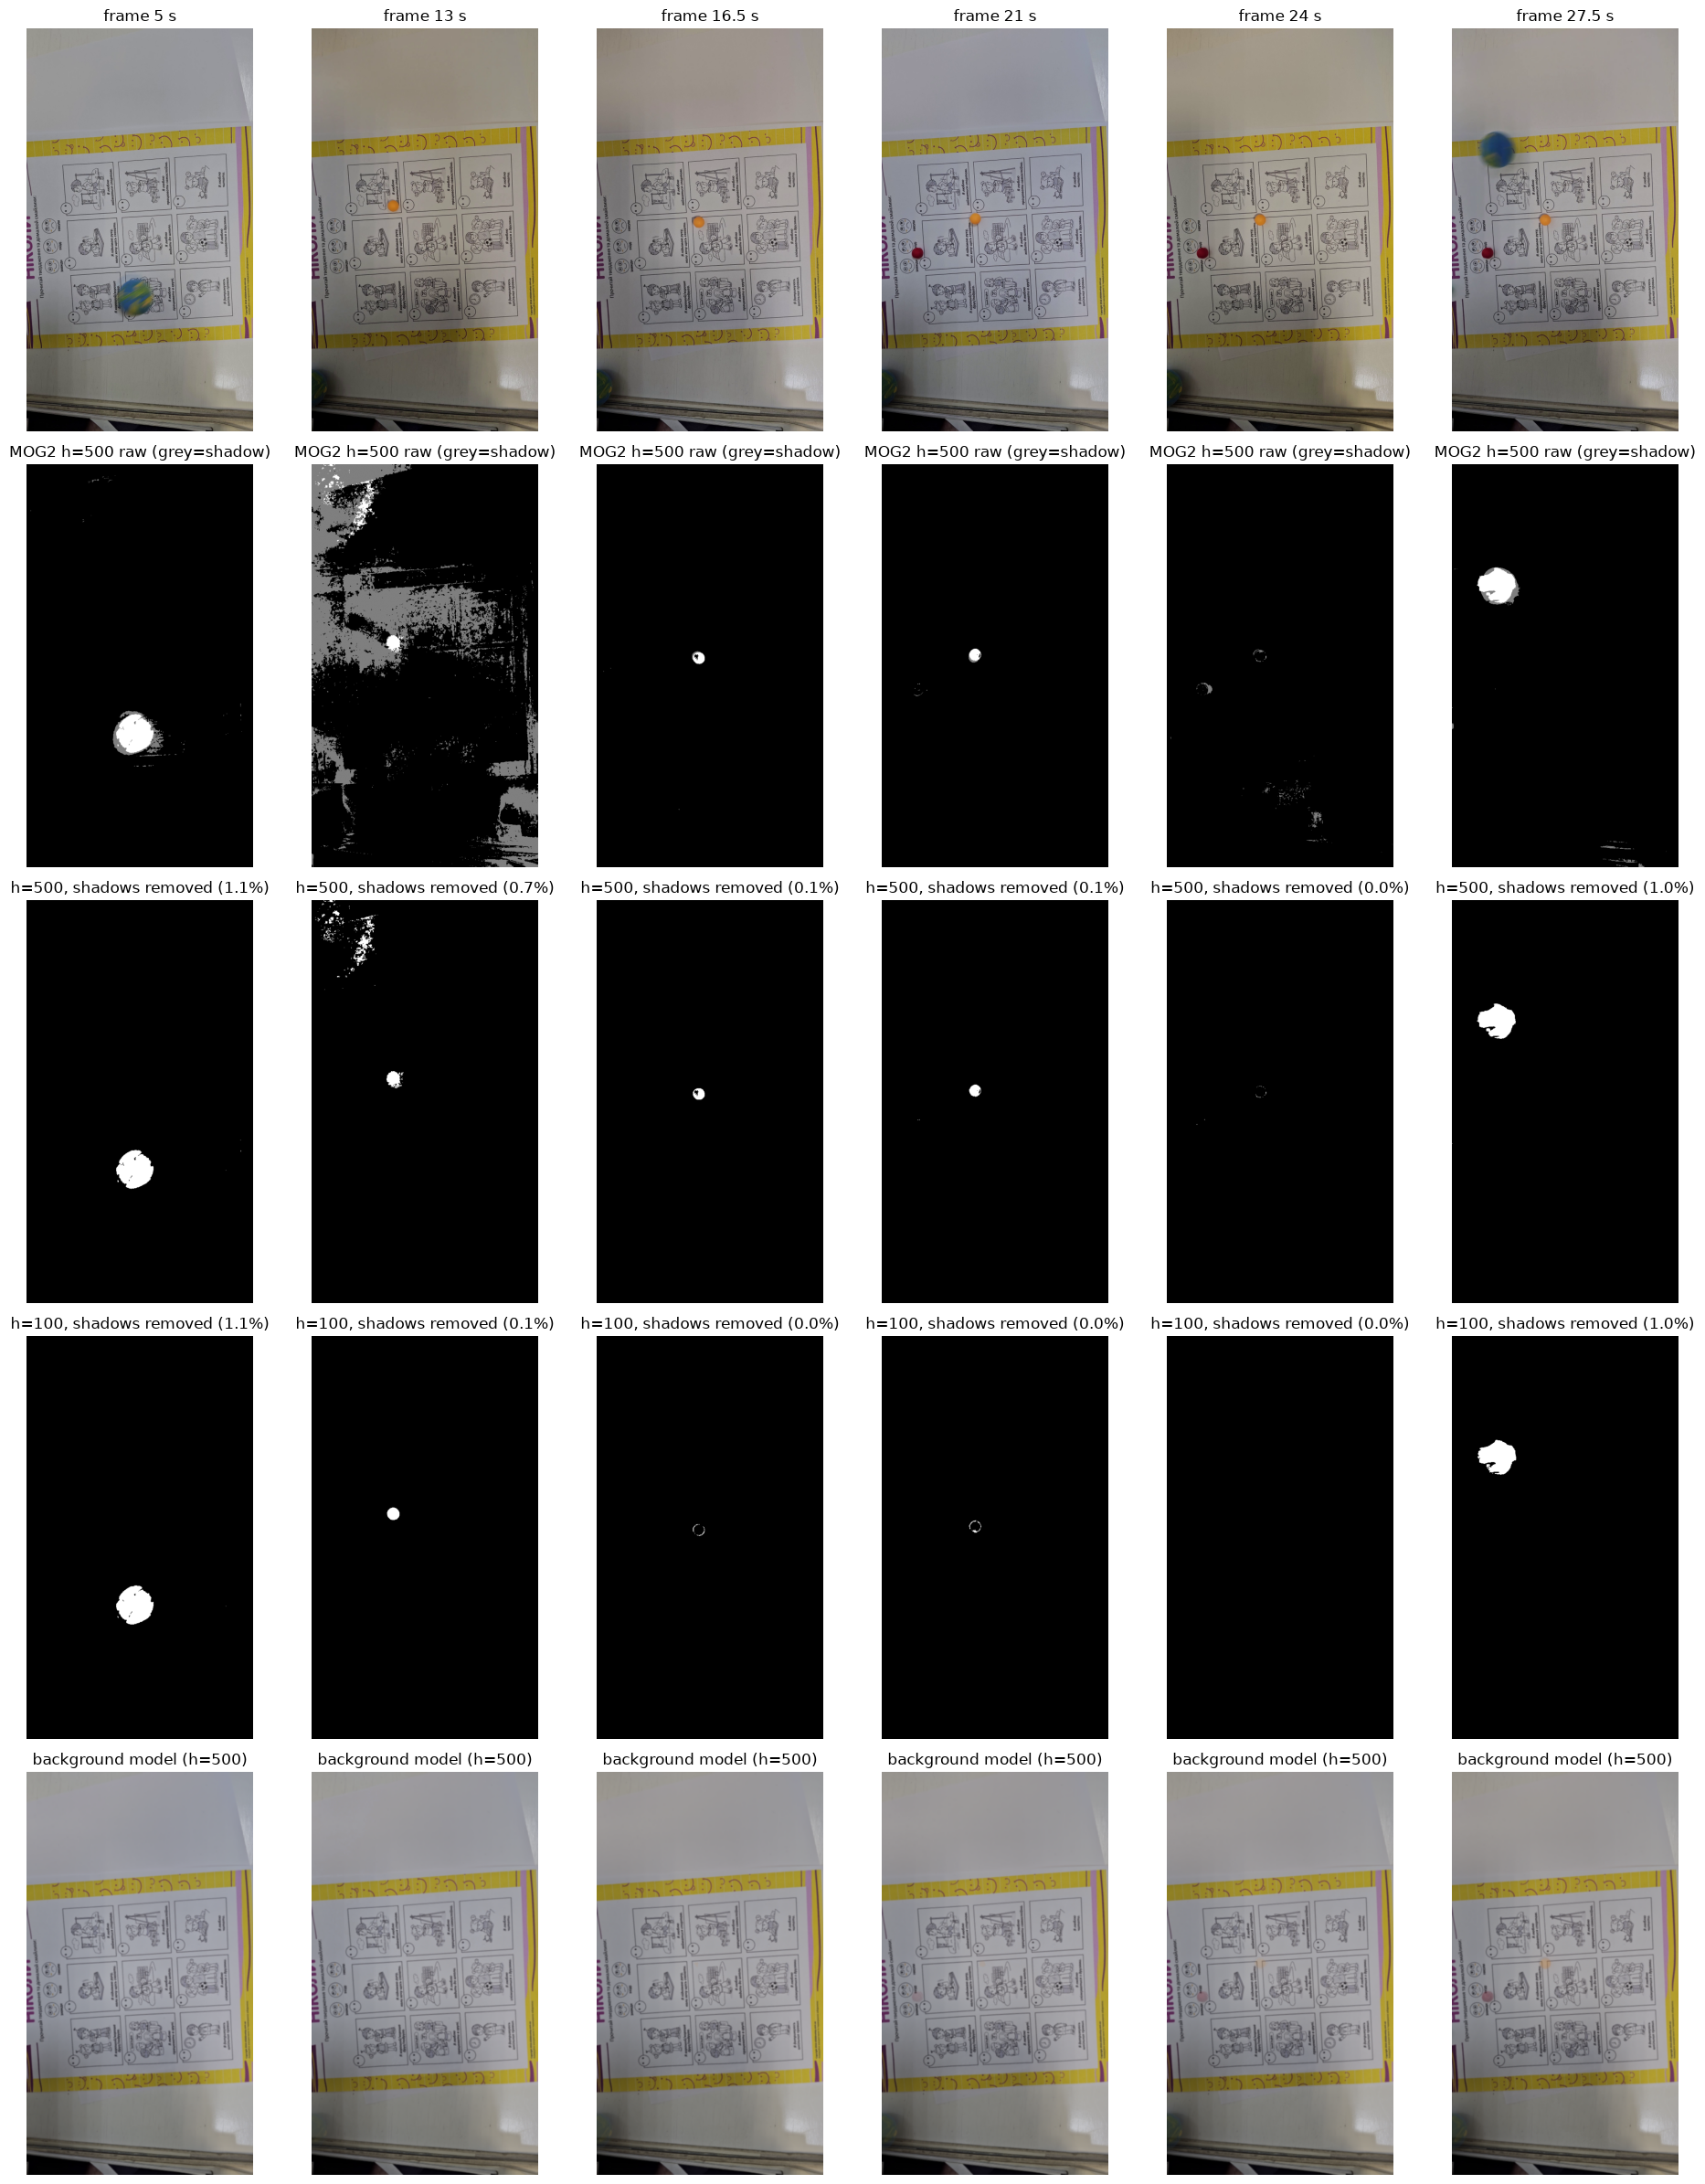

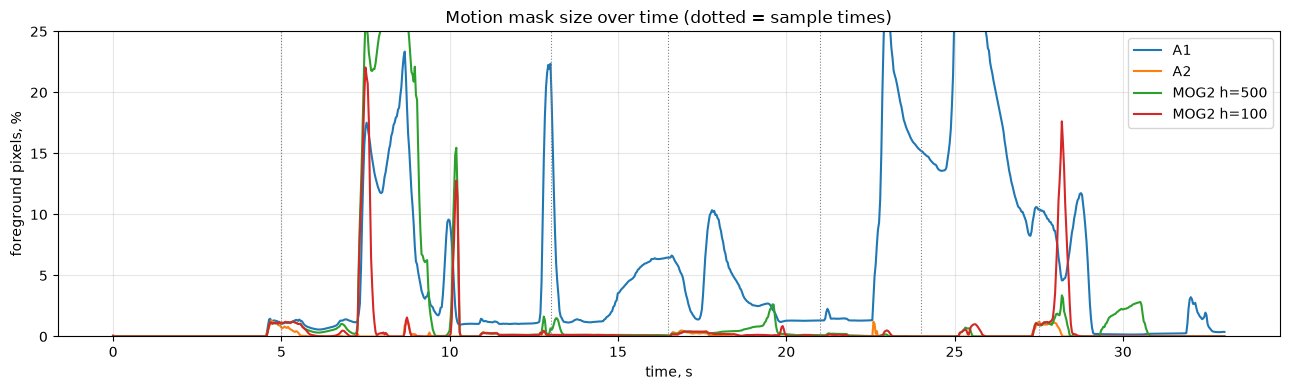

In [16]:
VAR_THR = 16
mog_slow = cv2.createBackgroundSubtractorMOG2(history=500, varThreshold=VAR_THR, detectShadows=True)
mog_fast = cv2.createBackgroundSubtractorMOG2(history=100, varThreshold=VAR_THR, detectShadows=True)

cap = cv2.VideoCapture(str(VIDEO)); assert cap.isOpened()
snaps, curves, prev, i = {}, {"A1": [], "A2": [], "MOG2 h=500": [], "MOG2 h=100": []}, None, 0
ms_mog = []
while True:
    ok, f = cap.read()
    if not ok: break
    small, gray = prep(f)
    blur = cv2.GaussianBlur(small, (BLUR, BLUR), 0)

    t0 = time.perf_counter(); m_slow = mog_slow.apply(blur); ms_mog.append((time.perf_counter() - t0) * 1000)
    m_fast = mog_fast.apply(blur)
    a1 = cv2.absdiff(gray, ref_gray) > THR
    a2 = (cv2.absdiff(gray, prev) > THR) if prev is not None else np.zeros_like(a1)

    curves["A1"].append(100 * a1.mean()); curves["A2"].append(100 * a2.mean())
    curves["MOG2 h=500"].append(100 * np.mean(m_slow == 255))
    curves["MOG2 h=100"].append(100 * np.mean(m_fast == 255))
    if i in cur_nos:
        snaps[i] = (small.copy(), m_slow.copy(), m_fast.copy(), mog_slow.getBackgroundImage())
    prev, i = gray, i + 1
cap.release()
print(f"processed {i} frames | MOG2 apply: {np.mean(ms_mog):.1f} ms/frame")

# masks at the sample times
fig, ax = plt.subplots(5, len(SAMPLE_TIMES), figsize=(3.2 * len(SAMPLE_TIMES), 24))
for j, (t, k) in enumerate(zip(SAMPLE_TIMES, cur_nos)):
    small, m_slow, m_fast, bg = snaps[k]
    fg = 100 * np.mean(m_slow == 255); sh = 100 * np.mean(m_slow == 127); fgf = 100 * np.mean(m_fast == 255)
    print(f"t={t:5.1f}s  MOG2 h=500: fg {fg:5.2f}%  shadow {sh:5.2f}%  |  MOG2 h=100: fg {fgf:5.2f}%")
    ax[0, j].imshow(cv2.cvtColor(small, cv2.COLOR_BGR2RGB)); ax[0, j].set_title(f"frame {t} s")
    ax[1, j].imshow(m_slow, cmap="gray", vmin=0, vmax=255); ax[1, j].set_title("MOG2 h=500 raw (grey=shadow)")
    ax[2, j].imshow(m_slow == 255, cmap="gray"); ax[2, j].set_title(f"h=500, shadows removed ({fg:.1f}%)")
    ax[3, j].imshow(m_fast == 255, cmap="gray"); ax[3, j].set_title(f"h=100, shadows removed ({fgf:.1f}%)")
    ax[4, j].imshow(cv2.cvtColor(bg, cv2.COLOR_BGR2RGB)); ax[4, j].set_title("background model (h=500)")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(RESULTS / "task10_step2_mog2.png", dpi=80); plt.show()

# foreground share over the whole video, all four methods
tt = np.arange(i) / fps
plt.figure(figsize=(13, 4))
for name, c in curves.items():
    plt.plot(tt, c, label=name)
for t in SAMPLE_TIMES: plt.axvline(t, color="gray", ls=":", lw=0.8)
plt.ylim(0, 25); plt.xlabel("time, s"); plt.ylabel("foreground pixels, %"); plt.grid(alpha=0.3); plt.legend()
plt.title("Motion mask size over time (dotted = sample times)")
plt.tight_layout(); plt.savefig(RESULTS / "task10_step2_fg_over_time.png", dpi=100); plt.show()

Step 3: Morphology and the minimum area

MOG2 h=100, 5 s      raw (3, 1) -> open (1, 1) -> close (1, 1)   (all blobs, blobs >= MIN_AREA)
MOG2 h=100, 13 s     raw (1, 1) -> open (1, 1) -> close (1, 1)   (all blobs, blobs >= MIN_AREA)
MOG2 h=100, 27.5 s   raw (3, 1) -> open (2, 1) -> close (1, 1)   (all blobs, blobs >= MIN_AREA)
MOG2 h=500, 13 s     raw (145, 5) -> open (11, 3) -> close (5, 4)   (all blobs, blobs >= MIN_AREA)
A2, 5 s              raw (15, 4) -> open (5, 4) -> close (2, 2)   (all blobs, blobs >= MIN_AREA)
A2, 27.5 s           raw (2, 2) -> open (2, 2) -> close (1, 1)   (all blobs, blobs >= MIN_AREA)


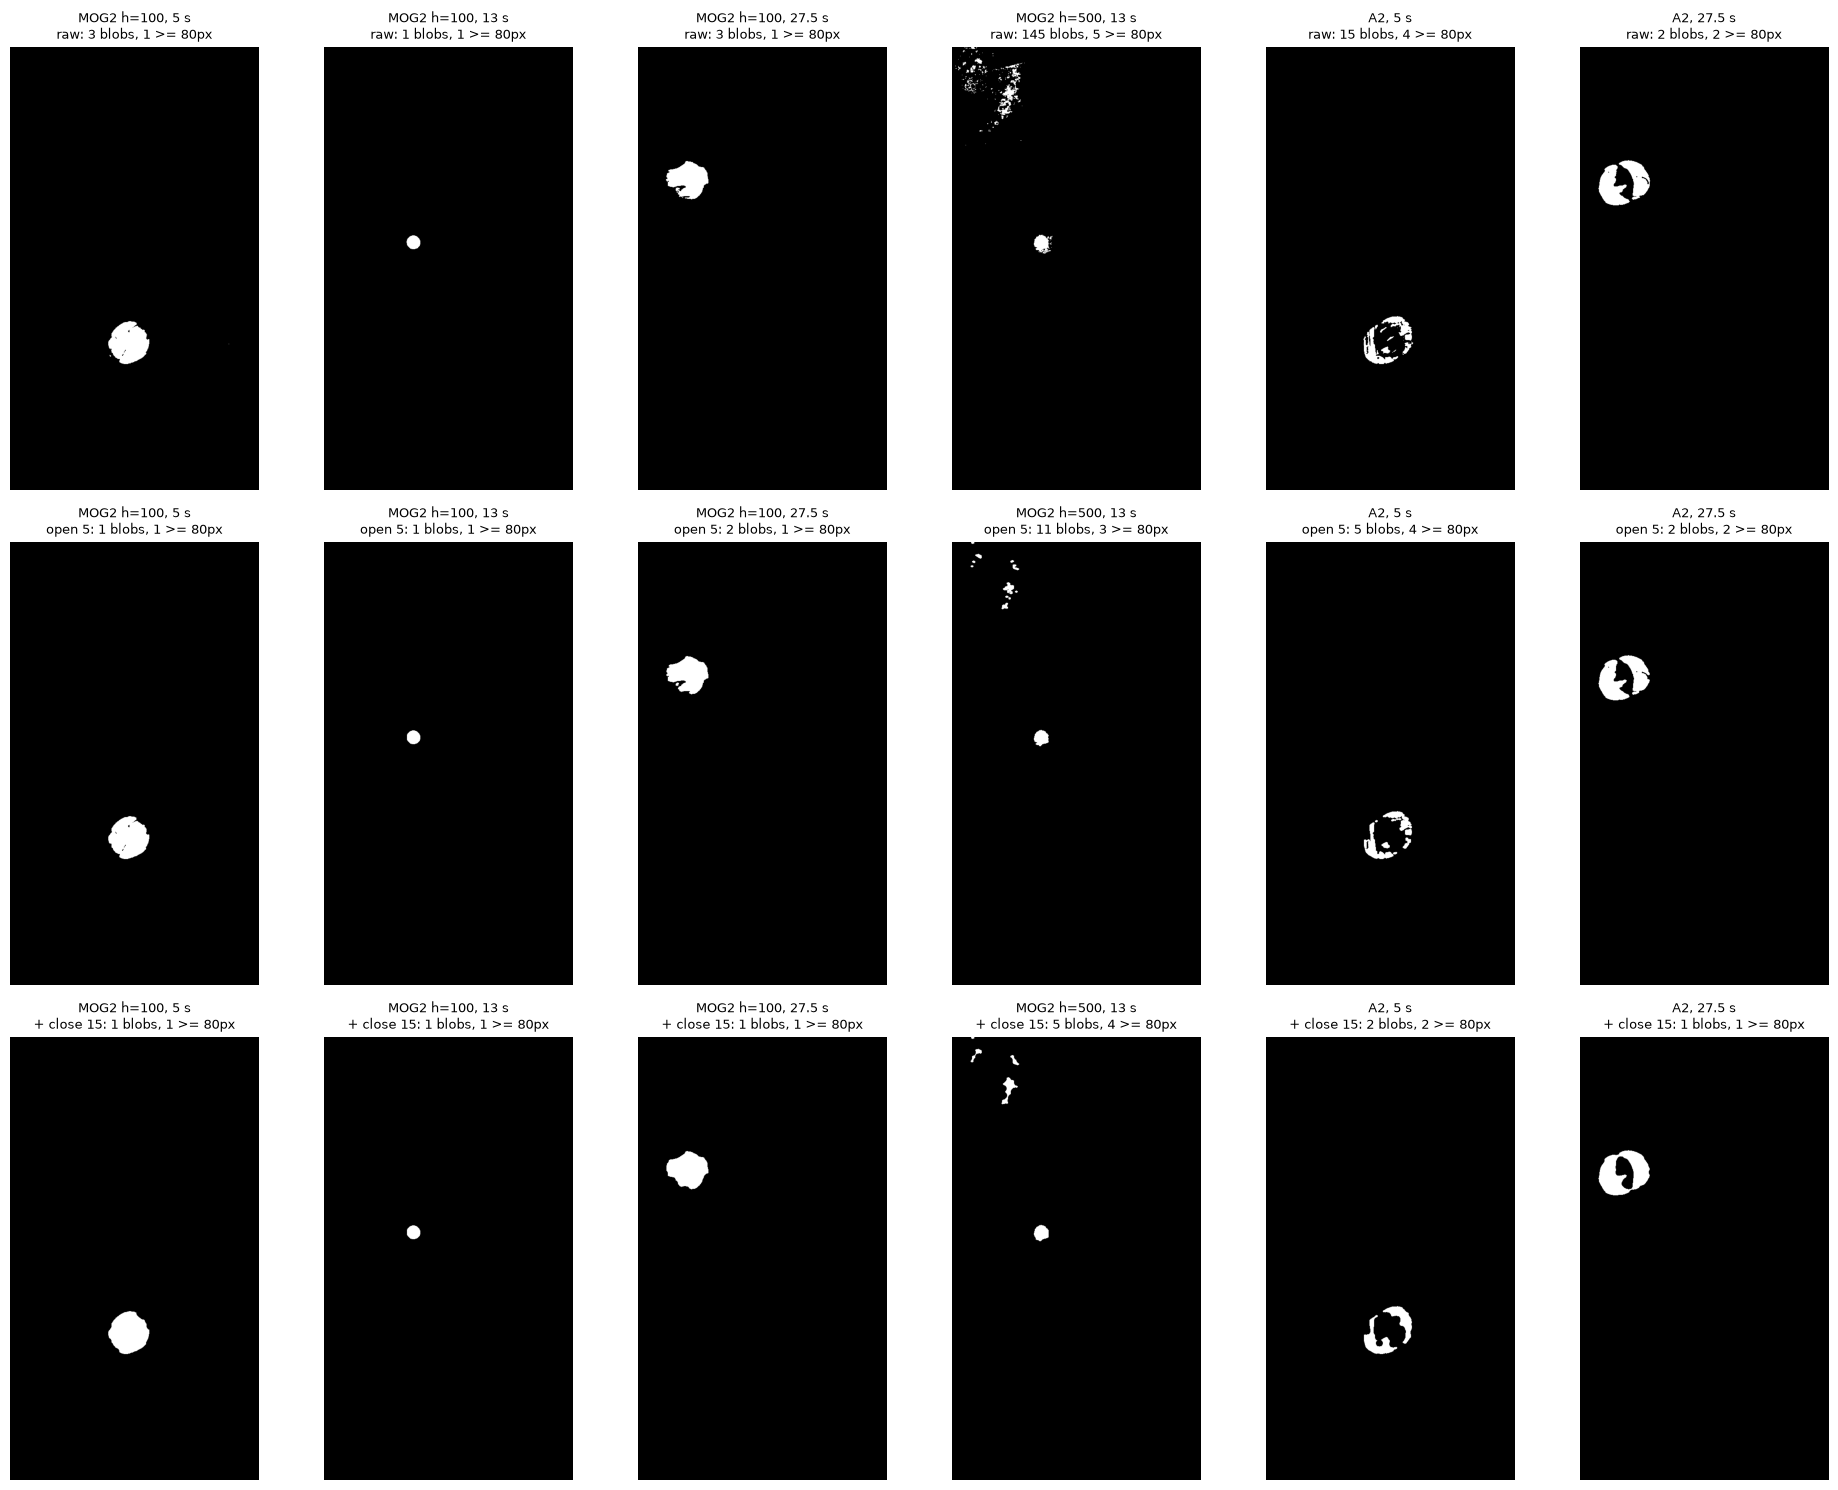

In [17]:
K_OPEN, K_CLOSE, MIN_AREA = 5, 15, 80
k_open  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (K_OPEN, K_OPEN))
k_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (K_CLOSE, K_CLOSE))

def count_blobs(mask):
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return len(cnts), sum(cv2.contourArea(c) >= MIN_AREA for c in cnts)

def a2_mask(k):
    _, cur = prep(frames[k]); _, prev_ = prep(frames[k - 1])
    return np.where(cv2.absdiff(cur, prev_) > THR, 255, 0).astype(np.uint8)

fg = lambda m: np.where(m == 255, 255, 0).astype(np.uint8)        # MOG2: keep foreground, drop shadows
k_at = dict(zip(SAMPLE_TIMES, cur_nos))
cases = [("MOG2 h=100, 5 s",    fg(snaps[k_at[5]][2])),
         ("MOG2 h=100, 13 s",   fg(snaps[k_at[13]][2])),
         ("MOG2 h=100, 27.5 s", fg(snaps[k_at[27.5]][2])),
         ("MOG2 h=500, 13 s",   fg(snaps[k_at[13]][1])),          # has the false patch top-left
         ("A2, 5 s",            a2_mask(k_at[5])),
         ("A2, 27.5 s",         a2_mask(k_at[27.5]))]

fig, ax = plt.subplots(3, len(cases), figsize=(3.2 * len(cases), 15))
for j, (name, raw) in enumerate(cases):
    opened = cv2.morphologyEx(raw, cv2.MORPH_OPEN, k_open)
    closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, k_close)
    for i, (stage, m) in enumerate([("raw", raw), (f"open {K_OPEN}", opened), (f"+ close {K_CLOSE}", closed)]):
        n_all, n_big = count_blobs(m)
        ax[i, j].imshow(m, cmap="gray"); ax[i, j].axis("off")
        ax[i, j].set_title(f"{name}\n{stage}: {n_all} blobs, {n_big} >= {MIN_AREA}px", fontsize=9)
    print(f"{name:20s} raw {count_blobs(raw)} -> open {count_blobs(opened)} -> close {count_blobs(closed)}"
          "   (all blobs, blobs >= MIN_AREA)")
plt.tight_layout(); plt.savefig(RESULTS / "task10_step3_morphology.png", dpi=80); plt.show()

STEP 5 5

a1        predicted at [np.int64(0), np.int64(2), np.int64(4), np.int64(6), np.int64(8), np.int64(10), np.int64(12), np.int64(14), np.int64(16), np.int64(18), np.int64(20), np.int64(22), np.int64(24), np.int64(26), np.int64(28), np.int64(30), np.int64(32)]:
          [np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(3), np.int64(2), np.int64(2), np.int64(2), np.int64(4), np.int64(5), np.int64(3), np.int64(3), np.int64(5), np.int64(3), np.int64(4), np.int64(1), np.int64(3)]
a2        predicted at [np.int64(0), np.int64(2), np.int64(4), np.int64(6), np.int64(8), np.int64(10), np.int64(12), np.int64(14), np.int64(16), np.int64(18), np.int64(20), np.int64(22), np.int64(24), np.int64(26), np.int64(28), np.int64(30), np.int64(32)]:
          [np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0)]
mog2_500  predicted 

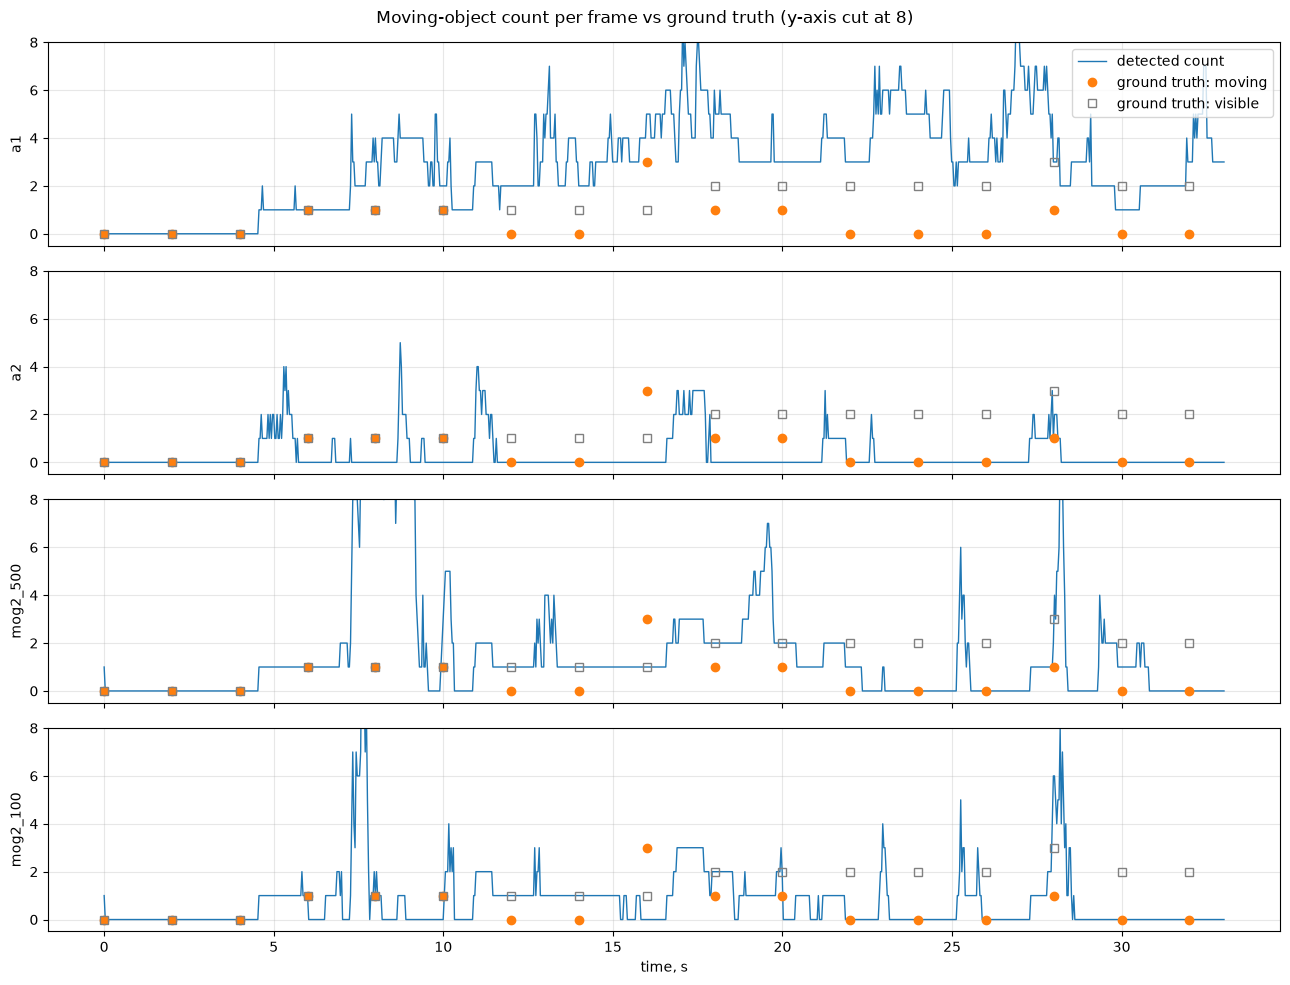

In [18]:
import csv, json
import numpy as np, matplotlib.pyplot as plt
from pathlib import Path
RESULTS = Path("results")

# time_s: (visible, moving)  -- CHECK each line against results/check_task10_motion_sheet.png
GT = {0: (0, 0), 2: (0, 0), 4: (0, 0),
      6: (1, 1),  8: (1, 1), 10: (1, 1),          # ? big ball passing / entering - check
      12: (1, 0), 14: (1, 0),                     # orange ball resting
      16: (1, 3),                                 # ? three objects moving (visible may be 3)
      18: (2, 1), 20: (2, 1),                     # one moves slightly near the other
      22: (2, 0), 24: (2, 0), 26: (2, 0),         # both resting (green passed at ~21 s)
      28: (3, 1),                                 # big ball moves
      30: (2, 0), 32: (2, 0)}
METHODS = ["a1", "a2", "mog2_500", "mog2_100"]
WIN = 0.2                                          # +/- seconds around each moment (median count)

def load(m):
    with open(RESULTS / f"task10_{m}.csv") as f:
        rows = list(csv.DictReader(f))
    return np.array([float(r["time_s"]) for r in rows]), np.array([int(r["count"]) for r in rows])

table, data = [], {}
ts = np.array(sorted(GT)); gt_vis = np.array([GT[t][0] for t in ts]); gt_mov = np.array([GT[t][1] for t in ts])
for m in METHODS:
    t, c = load(m); data[m] = (t, c)
    pred = np.array([int(np.median(c[(t >= s - WIN) & (t <= s + WIN)])) for s in ts])
    s = json.loads((RESULTS / f"task10_{m}_summary.json").read_text())
    table.append(dict(method=m, fps=s["fps"],
                      exact_vs_moving_pct=round(100 * np.mean(pred == gt_mov), 1),
                      mae_vs_moving=round(float(np.mean(np.abs(pred - gt_mov))), 2),
                      exact_vs_visible_pct=round(100 * np.mean(pred == gt_vis), 1),
                      mae_vs_visible=round(float(np.mean(np.abs(pred - gt_vis))), 2),
                      overcount_pct=round(100 * np.mean(pred > gt_mov), 1),
                      undercount_pct=round(100 * np.mean(pred < gt_mov), 1)))
    print(f"{m:9s} predicted at {list(ts)}:\n          {list(pred)}")
print()
for r in table: print(r)
with open(RESULTS / "task10_comparison.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(table[0])); w.writeheader(); w.writerows(table)

fig, ax = plt.subplots(len(METHODS), 1, figsize=(13, 10), sharex=True)
for a, m in zip(ax, METHODS):
    t, c = data[m]
    a.plot(t, c, lw=1, label="detected count")
    a.plot(ts, gt_mov, "o", color="tab:orange", label="ground truth: moving")
    a.plot(ts, gt_vis, "s", mfc="none", color="gray", label="ground truth: visible")
    a.set_ylabel(m); a.set_ylim(-0.5, 8); a.grid(alpha=0.3)
ax[0].legend(loc="upper right"); ax[-1].set_xlabel("time, s")
fig.suptitle("Moving-object count per frame vs ground truth (y-axis cut at 8)")
plt.tight_layout(); plt.savefig(RESULTS / "task10_counts.png", dpi=100); plt.show()